### Determine which biomes/variables are most/least constraining

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import os, json, glob
import sys
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#############################################
# Setup
#############################################
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)

universal_param_names = param_info['u_params']
pft_param_names = param_info['pft_params']
n_universal_params = len(param_info['u_params'])
n_pft_params = len(param_info['pft_params']) # Number of parameters per PFT

# load observational data
obs = xr.open_dataset(utils_dir + 'obs_statistics_byBiome.nc')

var_list = ['LAI','GPP','TVC','LH']
biome_names = []
biomes = ['1','2','3','4','5','6','7','8','9','10','11','12','13']
for b in biomes:
    biome_names.append(biome_info[b]['name'])

### Figure 4 biome-variable constraint strength

In [4]:
#############################################
# user mods
#############################################

I_tolerance = 3 # implausibility tolerance
out_dir = '../data/figure4_hm_output/'

In [ ]:
n_combos = len(var_list) * len(biomes)  # should be 52
nroy_samp = np.zeros(n_combos)
total_samp = np.zeros(n_combos)

files = sorted(glob.glob(out_dir + 'all_I_*.npy'))
for f in files:
    arr = np.load(f)  # shape: (:, 1000, 52)
    for ix in range(n_combos):
        slab = arr[:, :, ix].ravel()
        nroy_samp[ix] += (slab < 3).sum() # less than I=3 is nroy
        total_samp[ix] += slab.size
    del arr

# Reshape into (n_vars, n_biomes) and compute percentages
results = np.round(100 * (nroy_samp / total_samp), 1).reshape(len(var_list), len(biomes))


In [ ]:
# Plot
cmap = sns.cubehelix_palette(as_cmap=True, start=0.4, rot=-0.8, light=0.3, dark=1)

fig, ax = plt.subplots(figsize=(6, len(var_list) * 1.6))
im = ax.imshow((100-results.T), aspect='auto', cmap=cmap.reversed(), vmin=0, vmax=100)
ax.set_yticks(range(len(biomes)))
ax.set_yticklabels(biome_names, fontsize=12)
ax.set_xticks(range(len(var_list)))
ax.set_xticklabels(['LAI', 'GPP', 'VegC', 'LH'], fontsize=12)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Percent ruled out', fontsize=12)
plt.tight_layout()
plt.savefig('../figs/figure4_HMbiome_constraints.png',dpi=300, bbox_inches='tight')

### Figure S8: excluding emulator uncertainty

In [5]:
I_tolerance = 3 # implausibility tolerance
out_dir = '../data/figureS8_hm_output/'

In [6]:
n_combos = len(var_list) * len(biomes)  # should be 52
counts_below = np.zeros(n_combos)
total_elements = np.zeros(n_combos)

files = sorted(glob.glob(out_dir + 'all_I_*.npy'))
for f in files:
    arr = np.load(f)  # shape: (chunk_rows, 1000, 54)
    for ix in range(n_combos):
        slab = arr[:, :, ix].ravel()
        counts_below[ix] += (slab < 3).sum()
        total_elements[ix] += slab.size
    del arr

# Reshape into (n_vars, n_biomes) and compute percentages
results = np.round(100 * (counts_below / total_elements), 1).reshape(len(var_list), len(biomes))

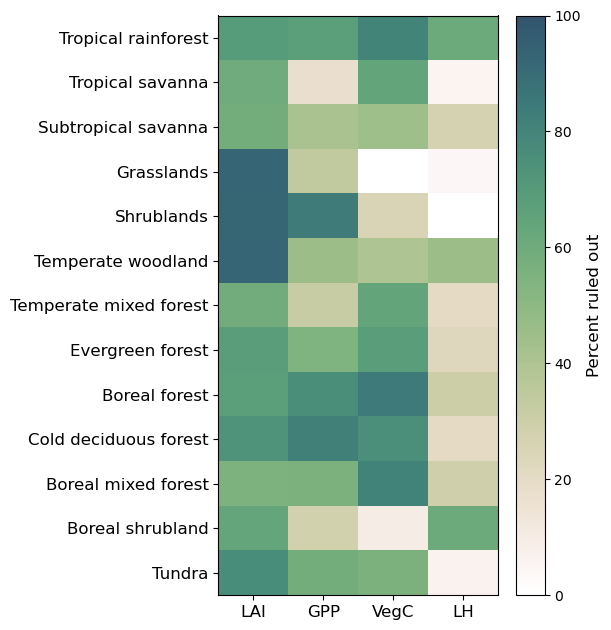

In [11]:
# Plot
cmap = sns.cubehelix_palette(as_cmap=True, start=0.4, rot=-0.8, light=0.3, dark=1)

fig, ax = plt.subplots(figsize=(6, len(var_list) * 1.6))
im = ax.imshow((100-results.T), aspect='auto', cmap=cmap.reversed(), vmin=0, vmax=100)
ax.set_yticks(range(len(biomes)))
ax.set_yticklabels(biome_names, fontsize=12)
ax.set_xticks(range(len(var_list)))
ax.set_xticklabels(['LAI', 'GPP', 'VegC', 'LH'], fontsize=12)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Percent ruled out', fontsize=12)
plt.tight_layout()
plt.savefig('../figs/SI_FigS8_HMbiome_constraints_noEmVar.png',dpi=300, bbox_inches='tight')